# SOFR Curve Calibrated from SOFR, Futures & Treasuries

Every number a counterparty-risk desk produces starts with a discount curve, and since the end of LIBOR the curve for U.S. dollar collateralised derivatives is the SOFR curve. Production desks build it from dealer quotes that are not free. This notebook shows how far public data can go, and which interpolation method gives forward rates a risk team can trust.

**What it does.** It builds a SOFR discounting curve and a Treasury zero curve for today's date with QuantLib, and tests which interpolation method gives the most trustworthy forward rates.

**Data.** SOFR fixings and 10 years of Treasury yields (FRED), the official daily par yield curve (U.S. Treasury), and the strip of 3-month SOFR futures (CME, via Yahoo Finance).

**Methods.** Curve bootstrapping (deposit + futures with convexity adjustment + OIS swaps), six interpolation schemes compared on exact repricing, forward smoothness and locality, and a sensitivity test on the swap-spread assumption.

**Key output.** A validated SOFR zero, forward and discount curve, the market-implied path of SOFR, and a one-page curve dashboard (PNG and interactive HTML).

## 1. Why a risk team cares about this curve

Every number a counterparty-risk desk produces starts with a discount curve. Potential future exposure, CVA and FVA, the value of a hedge, the mark-to-market of a swap book: each one discounts future cash flows. Since the LIBOR transition, the discount curve for USD collateralised derivatives is the **SOFR OIS curve**.

In a multilateral bank this curve is used every day to:

- **value the swap book** that hedges the bond portfolio and the borrowings, which is the starting point of PFE and XVA;
- **project floating cash flows** on SOFR-linked loans and swaps;
- **measure sensitivities** (DV01, key-rate risk), because a bad interpolation creates fake risk in tenors where nothing traded.

In production the curve is built from live dealer quotes for SOFR swaps, which are not free. This notebook shows how far public data alone can go:

| Curve segment | Instrument | Source |
|---|---|---|
| Overnight | SOFR fixing | FRED |
| 3 months – 2 years | 3M SOFR futures (CME) | Yahoo Finance |
| 2 – 30 years | OIS swap rate ≈ Treasury par yield + swap spread | U.S. Treasury + an explicit spread assumption |

The long end is the honest weak point. Treasuries are not SOFR swaps, and the difference between the two, the **swap spread**, has been negative for years, because balance-sheet costs make Treasuries expensive to hold relative to swaps.

The notebook therefore adds an explicit swap-spread assumption and shows how much it moves the curve. Reported swap trades would replace it.

## 2. The theory in five minutes

**Discount factors are the curve.** Everything else is a re-expression of $P(0,T)$, today's price of \$1 paid at $T$:

$$
\text{zero rate: } z(T) = -\frac{\ln P(0,T)}{T}
\qquad
\text{simple forward: } F(T_1,T_2) = \frac{1}{\tau(T_1,T_2)}\left(\frac{P(0,T_1)}{P(0,T_2)} - 1\right)
$$

**Bootstrapping** builds $P(0,T)$ one instrument at a time, from short to long. Each new instrument adds one unknown discount factor at its maturity (its *pillar*), and the solver picks the value that makes the instrument price exactly at its market quote. Earlier pillars are already fixed.

**SOFR futures.** A 3M SOFR future settles on the *compounded* SOFR over its reference quarter. Its price is quoted as $100 - R$, so the implied rate is $R = 100 - \text{price}$. Futures are margined daily and forwards are not, so the futures rate sits slightly above the forward rate. That gap is the **convexity adjustment**, approximated here with the Ho–Lee formula

$$
\text{CA} \approx \tfrac{1}{2}\,\sigma^2\, T_1\, T_2 ,
$$

with $\sigma$ the normal volatility of short rates. It is tiny under 2 years, which is exactly why we only use futures up to 2 years.

**Interpolation.** Between pillars the curve is not observed, so we have to choose how to fill the gaps. The choice matters more for **forward rates**, which are derivatives of the curve, than for zero rates:

| Method | What is interpolated | Forwards | Local? |
|---|---|---|---|
| Flat forward / log-linear discount | log discount factors, linearly | step function (jumps at every pillar) | yes |
| Linear zero | zero rates, linearly | saw-tooth | yes |
| Cubic zero | zero rates, natural cubic spline | smooth | **no**: one quote moves the whole curve |
| Log-cubic discount | log discount factors, cubic spline | very smooth | **no** |
| Monotone-convex (Hagan–West) | forwards, with shape preservation | smooth and positive | mostly |

There is no free lunch: smooth methods spread a local change across the whole curve, and local methods produce ugly forwards. We measure both effects below instead of picking by habit.

## 3. Setup

Imports, folders, credentials and a small caching helper. Every download goes through `cached()`, which stores the result in `data/` (excluded from Git) and reuses it for 12 hours. If a source is down, the notebook falls back to the last saved copy and tells you so.

In [1]:
# --- Standard library
import datetime as dt
import io
import logging
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import QuantLib as ql
import requests
import yfinance as yf
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots

warnings.filterwarnings("ignore", category=FutureWarning)
logging.getLogger("yfinance").setLevel(logging.CRITICAL)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# --- Folders: everything is relative to this notebook
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"  # cached downloads (never committed)
OUT_DIR = PROJECT_DIR / "outputs"  # charts and tables (committed)
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

# --- Credentials: read from the .env file at the repo root
load_dotenv(find_dotenv(usecwd=True))
import os

FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )

BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

print(
    f"QuantLib {ql.__version__} · pandas {pd.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

QuantLib 1.44 · pandas 3.0.6 · run on 2026-10-18


In [2]:
# --- Caching helper
# Downloads are cached as Parquet files. A fresh cache is reused; a failed
# download falls back to the last cached copy so the notebook still runs
# offline.
CACHE_HOURS = 12


def cached(
    name: str, fetch, max_age_hours: float = CACHE_HOURS
) -> pd.DataFrame:
    path = DATA_DIR / f"{name}.parquet"
    if path.exists():
        age_h = (time.time() - path.stat().st_mtime) / 3600
        if age_h < max_age_hours:
            return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy from "
                f"{dt.datetime.fromtimestamp(path.stat().st_mtime):%Y-%m-%d %H:%M}"
            )
            return pd.read_parquet(path)
        raise

In [3]:
# --- Chart style
# One validated categorical palette, used in a fixed order across every chart,
# thin lines, light grid and muted text, so the data carries the ink.
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE_RAMP = [
    "#cde2fb",
    "#9ec5f4",
    "#6da7ec",
    "#3987e5",
    "#256abf",
    "#184f95",
    "#0d366b",
]

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
})


def save_fig(fig, name):
    """Save a matplotlib figure to outputs/ (PNG renders on GitHub)."""
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 4. Data

### 4.1 Treasury par yield curve (U.S. Treasury)

The Treasury publishes the official **par yield curve** every business day: the yield at which a new Treasury of each maturity would price at par. One CSV per year is available at
`https://home.treasury.gov/resource-center/data-chart-center/interest-rates/daily-treasury-rates.csv/<YEAR>/all?type=daily_treasury_yield_curve&field_tdr_date_value=<YEAR>&_format=csv`.

Column names change over time (the 1.5-month and 4-month bills were added recently), so we read the tenor out of each column name instead of hard-coding them.

In [4]:
TREASURY_URL = (
    "https://home.treasury.gov/resource-center/data-chart-center/interest-rates/"
    "daily-treasury-rates.csv/{year}/all?type=daily_treasury_yield_curve"
    "&field_tdr_date_value={year}&page&_format=csv"
)


def tenor_in_years(column: str):
    """
    '3 Mo' -> 0.25, '1.5 Month' -> 0.125, '10 Yr' -> 10.0; anything else ->
    None.
    """
    match = re.match(r"^\s*([\d.]+)\s*(Mo|Month|Yr|Year)", column)
    if not match:
        return None
    value, unit = float(match.group(1)), match.group(2)
    return value / 12 if unit.startswith("Mo") else value


def fetch_treasury_par_curves() -> pd.DataFrame:
    """
    Download this year's and last year's daily par curves into a long table.
    """
    frames = []
    for year in (dt.date.today().year - 1, dt.date.today().year):
        text = requests.get(
            TREASURY_URL.format(year=year), headers=BROWSER_HEADERS, timeout=30
        ).text
        raw = pd.read_csv(io.StringIO(text))
        if raw.empty:
            continue
        raw["date"] = pd.to_datetime(raw["Date"], format="%m/%d/%Y")
        tenor_cols = {
            c: tenor_in_years(c)
            for c in raw.columns
            if tenor_in_years(c) is not None
        }
        long = raw.melt(
            id_vars="date",
            value_vars=list(tenor_cols),
            var_name="column",
            value_name="par_yield",
        )
        long["tenor"] = long["column"].map(tenor_cols)
        frames.append(long[["date", "tenor", "par_yield"]])
    return (
        pd.concat(frames)
        .dropna()
        .sort_values(["date", "tenor"])
        .reset_index(drop=True)
    )


treasury_long = cached("treasury_par_curves", fetch_treasury_par_curves)
treasury_par = treasury_long.pivot(
    index="date", columns="tenor", values="par_yield"
).sort_index()

# The evaluation date of the whole notebook = the latest official Treasury
# curve.
EVAL_DATE = treasury_par.index.max().date()
par_today = treasury_par.loc[pd.Timestamp(EVAL_DATE)].dropna()

print(
    f"{len(treasury_par)} daily curves loaded · evaluation date ="
    f" {EVAL_DATE:%Y-%m-%d}"
)
par_today.rename("par yield (%)").to_frame().T

448 daily curves loaded · evaluation date = 2026-10-16


tenor,0.0833,0.1250,0.1667,0.2500,0.3333,0.5000,1.0000,2.0000,3.0000,5.0000,7.0000,10.0000,20.0000,30.0000
par yield (%),4.1200,4.1400,4.1700,4.2600,4.3200,4.3400,4.4600,4.7400,4.8200,4.8900,4.9800,5.0900,5.4700,5.4300


### 4.2 SOFR fixings and 10 years of Treasury history (FRED)

- **`SOFR`** is the overnight fixing published by the New York Fed. It anchors the very first point of the curve.
- The **`DGS*`** series are the Treasury constant-maturity yields. We only use them for the historical context below; the curve itself uses the official par curve above.

In [5]:
fred = Fred(api_key=FRED_API_KEY)
HISTORY_START = EVAL_DATE - dt.timedelta(days=365 * 10)

FRED_TREASURY_SERIES = {  # FRED id -> tenor in years
    "DGS1MO": 1 / 12,
    "DGS3MO": 0.25,
    "DGS6MO": 0.5,
    "DGS1": 1,
    "DGS2": 2,
    "DGS3": 3,
    "DGS5": 5,
    "DGS7": 7,
    "DGS10": 10,
    "DGS20": 20,
    "DGS30": 30,
}


def fetch_sofr() -> pd.DataFrame:
    s = fred.get_series(
        "SOFR", observation_start=EVAL_DATE - dt.timedelta(days=3 * 365)
    ).dropna()
    return s.rename("sofr").rename_axis("date").reset_index()


def fetch_treasury_history() -> pd.DataFrame:
    frames = []
    for series_id, tenor in FRED_TREASURY_SERIES.items():
        s = fred.get_series(
            series_id, observation_start=HISTORY_START
        ).dropna()
        frames.append(
            pd.DataFrame({"date": s.index, "tenor": tenor, "yield": s.values})
        )
    return pd.concat(frames, ignore_index=True)


sofr_fixings = (
    cached("fred_sofr", fetch_sofr).set_index("date")["sofr"].sort_index()
)
ust_history = (
    cached("fred_treasury_history", fetch_treasury_history)
    .pivot(index="date", columns="tenor", values="yield")
    .sort_index()
)

# The SOFR fixing for day t is published on t+1, so we take the latest one on
# or before EVAL_DATE.
sofr_today = sofr_fixings.loc[: pd.Timestamp(EVAL_DATE)].iloc[-1]
sofr_date = sofr_fixings.loc[: pd.Timestamp(EVAL_DATE)].index[-1].date()
print(
    f"SOFR fixing used: {sofr_today:.2f}% ({sofr_date:%Y-%m-%d}) · Treasury"
    f" history: {ust_history.index.min():%Y-%m-%d} →"
    f" {ust_history.index.max():%Y-%m-%d}"
)

SOFR fixing used: 3.89% (2026-10-15) · Treasury history: 2016-10-18 → 2026-10-15


### 4.3 3-month SOFR futures (CME, via Yahoo Finance)

Quarterly contracts expire on the IMM dates (March, June, September, December). Each one covers the quarter that starts on the third Wednesday of its month. Yahoo lists them as `SR3<month code><year>.CME`, e.g. `SR3Z26.CME` for December 2026, where H = Mar, M = Jun, U = Sep, Z = Dec.

We generate the next 12 contracts, download their closing prices, and keep the last close on or before the evaluation date.

In [6]:
MONTH_CODES = {3: "H", 6: "M", 9: "U", 12: "Z"}


def third_wednesday(year: int, month: int) -> dt.date:
    """IMM date: the third Wednesday of the month."""
    first = dt.date(year, month, 1)
    # weekday(): Monday=0 ... Wednesday=2
    offset = (2 - first.weekday()) % 7
    return first + dt.timedelta(days=offset + 14)


def upcoming_sofr_contracts(after: dt.date, n: int = 12) -> pd.DataFrame:
    """
    The next n quarterly 3M SOFR contracts whose reference quarter starts after
    `after`.
    """
    rows, year, month = [], after.year, 3
    while len(rows) < n:
        start = third_wednesday(year, month)
        if start > after:
            end_year, end_month = (
                (year, month + 3) if month < 12 else (year + 1, 3)
            )
            rows.append({
                "ticker": f"SR3{MONTH_CODES[month]}{year % 100:02d}.CME",
                "ref_month": month,
                "ref_year": year,
                "ref_start": start,
                "ref_end": third_wednesday(end_year, end_month),
            })
        month += 3
        if month > 12:
            month, year = 3, year + 1
    return pd.DataFrame(rows)


contracts = upcoming_sofr_contracts(EVAL_DATE + dt.timedelta(days=2))


def fetch_futures_prices() -> pd.DataFrame:
    prices = yf.download(
        contracts["ticker"].tolist(),
        start=EVAL_DATE - dt.timedelta(days=20),
        end=EVAL_DATE + dt.timedelta(days=5),
        progress=False,
        auto_adjust=False,
    )["Close"]
    # a single ticker comes back as a Series
    if isinstance(prices, pd.Series):
        prices = prices.to_frame(contracts["ticker"].iloc[0])
    prices.index = pd.to_datetime(prices.index).tz_localize(None)
    # yfinance versions name these differently
    prices.index.name, prices.columns.name = "date", None
    long = prices.reset_index().melt(
        id_vars="date", var_name="ticker", value_name="price"
    )
    return long.dropna()


futures_prices = cached("yahoo_sofr_futures", fetch_futures_prices)
# Yahoo stamps futures quotes with the *next* trading session (a Friday close
# can show up dated Monday), so we accept quotes up to four calendar days after
# the evaluation date.
last_close = (
    futures_prices[
        futures_prices["date"]
        <= pd.Timestamp(EVAL_DATE) + pd.Timedelta(days=4)
    ]
    .sort_values("date")
    .groupby("ticker")
    .last()
)

futures = contracts.merge(
    last_close, left_on="ticker", right_index=True, how="inner"
)
futures["implied_rate"] = 100 - futures["price"]  # % per annum
missing = sorted(set(contracts["ticker"]) - set(futures["ticker"]))
print(
    f"{len(futures)} contracts priced"
    + (f" · no data for {', '.join(missing)}" if missing else "")
)
futures[["ticker", "ref_start", "ref_end", "price", "implied_rate"]]

12 contracts priced


,ticker,ref_start,ref_end,price,implied_rate
0,SR3Z26.CME,2026-12-16,2027-03-17,95.7700,4.2300
1,SR3H27.CME,2027-03-17,2027-06-16,95.5200,4.4800
2,SR3M27.CME,2027-06-16,2027-09-15,95.3800,4.6200
3,SR3U27.CME,2027-09-15,2027-12-15,95.3400,4.6600
4,SR3Z27.CME,2027-12-15,2028-03-15,95.3550,4.6450
5,SR3H28.CME,2028-03-15,2028-06-21,95.3700,4.6300
6,SR3M28.CME,2028-06-21,2028-09-20,95.3800,4.6200
7,SR3U28.CME,2028-09-20,2028-12-20,95.3850,4.6150
8,SR3Z28.CME,2028-12-20,2029-03-21,95.4000,4.6000
9,SR3H29.CME,2029-03-21,2029-06-20,95.4150,4.5850


## 5. A first look at the inputs

Before building anything we look at what the market is telling us. Three questions:

1. Where is the curve today versus a year ago?
2. What path of SOFR is priced into the futures strip?
3. How unusual is today's curve shape in a 10-year context?

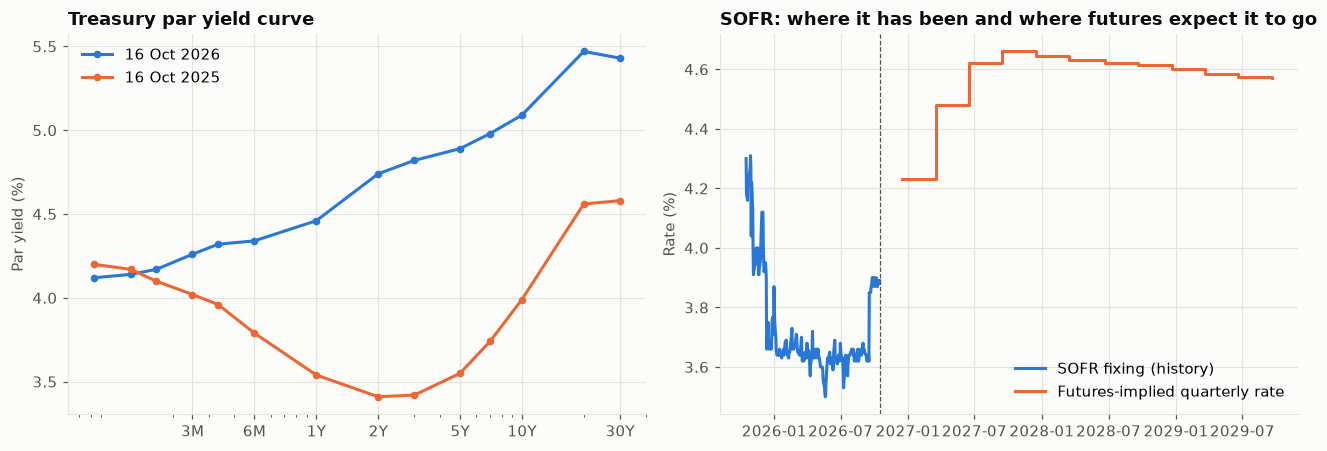

In [7]:
# --- Chart 1: today's par curve vs one year ago
year_ago = treasury_par.index[
    treasury_par.index <= pd.Timestamp(EVAL_DATE) - pd.Timedelta(days=365)
].max()
par_year_ago = treasury_par.loc[year_ago].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.plot(
    par_today.index,
    par_today.values,
    marker="o",
    ms=4,
    label=f"{EVAL_DATE:%d %b %Y}",
)
ax.plot(
    par_year_ago.index,
    par_year_ago.values,
    marker="o",
    ms=4,
    label=f"{year_ago:%d %b %Y}",
)
ax.set_xscale("log")
ax.set_xticks(
    [0.25, 0.5, 1, 2, 5, 10, 30], ["3M", "6M", "1Y", "2Y", "5Y", "10Y", "30Y"]
)
ax.set_title("Treasury par yield curve")
ax.set_ylabel("Par yield (%)")
ax.legend()

# --- Chart 2: SOFR fixings and the path implied by the futures strip
ax = axes[1]
recent = sofr_fixings.loc[pd.Timestamp(EVAL_DATE) - pd.Timedelta(days=365) :]
ax.plot(recent.index, recent.values, label="SOFR fixing (history)")
ax.step(
    pd.to_datetime(futures["ref_start"]),
    futures["implied_rate"],
    where="post",
    label="Futures-implied quarterly rate",
    color=PALETTE[1],
)
ax.axvline(pd.Timestamp(EVAL_DATE), color=INK_2, lw=0.8, ls="--")
ax.set_title("SOFR: where it has been and where futures expect it to go")
ax.set_ylabel("Rate (%)")
ax.legend()
plt.tight_layout()
save_fig(fig, "01_inputs_par_curve_and_sofr_path")
plt.show()

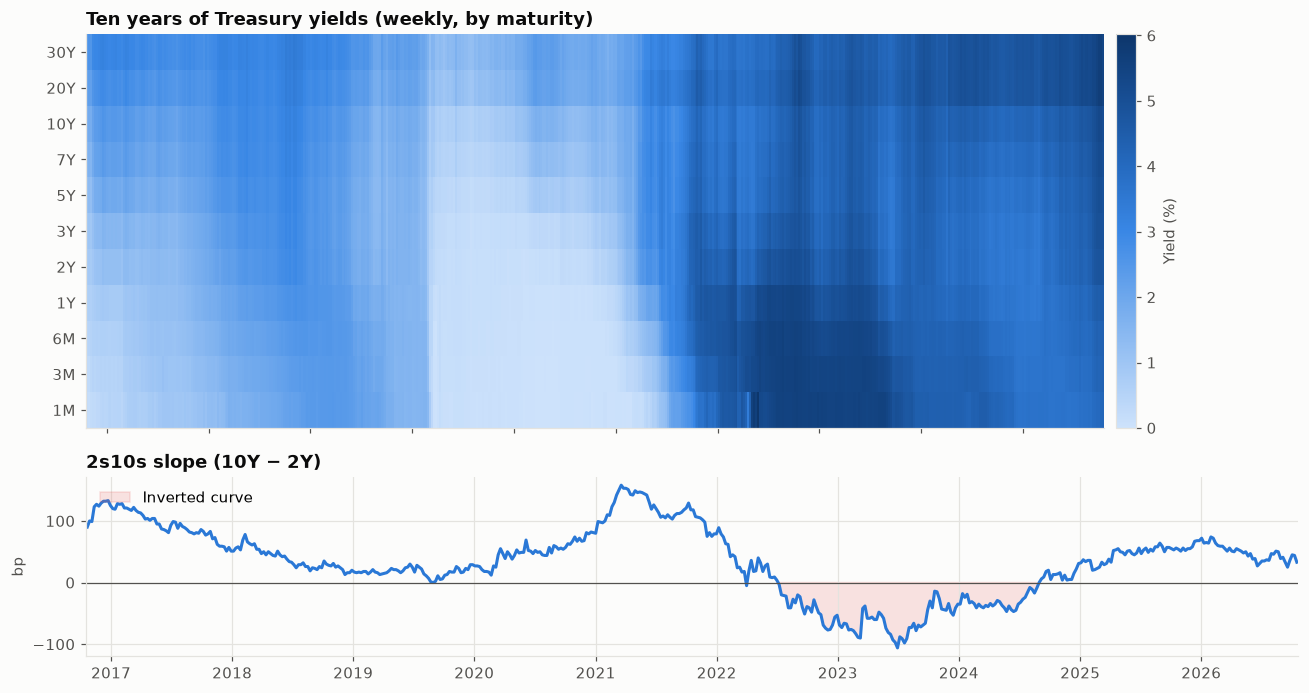

2s10s today: +33 bp · weeks inverted in the last 10 years: 22%


In [8]:
# --- Chart 3: 10 years of the Treasury curve as a heatmap + the 2s10s slope
weekly = ust_history.resample("W-FRI").last().dropna(how="all")
spread_2s10s = (weekly[10] - weekly[2]) * 100  # in basis points

fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 6.4),
    sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1]},
)
ax = axes[0]
mesh = ax.pcolormesh(
    weekly.index,
    np.arange(len(weekly.columns)),
    weekly.T.values,
    cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list(
        "blues", BLUE_RAMP
    ),
    shading="nearest",
)
ax.set_yticks(
    range(len(weekly.columns)),
    ["1M", "3M", "6M", "1Y", "2Y", "3Y", "5Y", "7Y", "10Y", "20Y", "30Y"],
)
ax.set_title("Ten years of Treasury yields (weekly, by maturity)")
ax.grid(False)
fig.colorbar(mesh, ax=ax, label="Yield (%)", pad=0.01)

ax = axes[1]
ax.plot(spread_2s10s.index, spread_2s10s.values, color=PALETTE[0])
ax.axhline(0, color=INK_2, lw=0.8)
ax.fill_between(
    spread_2s10s.index,
    spread_2s10s.values,
    0,
    where=spread_2s10s < 0,
    color=PALETTE[7],
    alpha=0.15,
    label="Inverted curve",
)
ax.set_title("2s10s slope (10Y − 2Y)")
ax.set_ylabel("bp")
ax.legend(loc="upper left")
plt.tight_layout()
save_fig(fig, "02_treasury_history_heatmap_2s10s")
plt.show()

print(
    f"2s10s today: {spread_2s10s.iloc[-1]:+.0f} bp · "
    f"weeks inverted in the last 10 years: {(spread_2s10s < 0).mean():.0%}"
)

## 6. Building the curves with QuantLib

### 6.1 Conventions and the swap-spread assumption

Three modelling choices sit on top of the data, and each one is stated explicitly here so it can be challenged:

- **Futures convexity.** Normal short-rate volatility of 100 bp a year in the Ho–Lee adjustment. Under 2 years this moves rates by at most a couple of basis points.
- **Futures horizon.** Futures are used only for reference quarters ending within 2 years, where they are the most liquid instrument and convexity is negligible.
- **Swap spreads (SOFR OIS minus Treasury par).** A term structure in basis points, broadly in line with where long-dated USD swap spreads have traded since 2023: negative and widening with maturity. This is the main assumption of the notebook. Section 7.3 measures how much it matters; reported swap trades would replace it.

In [9]:
ql_today = ql.Date(EVAL_DATE.day, EVAL_DATE.month, EVAL_DATE.year)
ql.Settings.instance().evaluationDate = ql_today

CURVE_DAY_COUNT = ql.Actual365Fixed()
US_GOVT = ql.UnitedStates(ql.UnitedStates.GovernmentBond)

# 100 bp normal vol for the Ho–Lee convexity adjustment
CONVEXITY_VOL = 0.01
FUTURES_MAX_YEARS = 2.0  # use futures only up to this horizon
OIS_TENORS = [2, 3, 5, 7, 10, 15, 20, 30]

# SOFR OIS minus Treasury par, in bp, by tenor (years). Explicit assumption,
# see the text above.
SWAP_SPREAD_BP = {
    2: -15,
    3: -20,
    5: -25,
    7: -30,
    10: -40,
    15: -55,
    20: -65,
    30: -75,
}


def to_ql_date(d) -> ql.Date:
    d = pd.Timestamp(d)
    return ql.Date(d.day, d.month, d.year)


def treasury_par_at(tenor_years: float) -> float:
    """
    Par yield (%) at any tenor, linear in maturity between published points
    (for 15Y).
    """
    return float(
        np.interp(tenor_years, par_today.index.astype(float), par_today.values)
    )


# Futures we keep: reference quarter ends within the futures horizon.
horizon = EVAL_DATE + dt.timedelta(days=int(365.25 * FUTURES_MAX_YEARS))
futures_used = futures[futures["ref_end"] <= horizon].copy()
futures_used["t_start"] = [
    (d - EVAL_DATE).days / 365 for d in futures_used["ref_start"]
]
futures_used["t_end"] = [
    (d - EVAL_DATE).days / 365 for d in futures_used["ref_end"]
]
futures_used["convexity_bp"] = (
    0.5
    * CONVEXITY_VOL**2
    * futures_used["t_start"]
    * futures_used["t_end"]
    * 1e4
)
print(
    f"Futures in the curve: {len(futures_used)} "
    f"(max convexity adjustment {futures_used['convexity_bp'].max():.2f} bp)"
)

Futures in the curve: 7 (max convexity adjustment 1.62 bp)


### 6.2 Treasury zero curve

Bills (≤ 1 year) are treated as zero-coupon bonds priced from their bond-equivalent yield. Notes and bonds (≥ 2 years) are par bonds paying semi-annual coupons equal to the par yield. Bootstrapping these bonds gives the Treasury discount curve, our benchmark for the SOFR curve.

In [10]:
def build_treasury_curve(curve_class=ql.PiecewiseLogCubicDiscount):
    """Bootstrap a Treasury zero curve from today's par yields."""
    helpers = []
    bond_dc = ql.ActualActual(ql.ActualActual.Bond)
    for tenor, par_yield in par_today.items():
        y = par_yield / 100
        # Bills are counted in weeks (4, 6, 8, 13, 17, 26, 52) so close tenors
        # never share a pillar.
        period = (
            ql.Period(int(round(tenor * 52)), ql.Weeks)
            if tenor < 1
            else ql.Period(int(round(tenor * 12)), ql.Months)
        )
        maturity = US_GOVT.advance(ql_today, period)
        # bill: zero coupon, price from the bond-equivalent yield
        if tenor <= 1:
            price = 100 / (1 + y / 2) ** (2 * tenor)
            schedule = ql.Schedule(
                ql_today,
                maturity,
                ql.Period(ql.Once),
                US_GOVT,
                ql.Unadjusted,
                ql.Unadjusted,
                ql.DateGeneration.Backward,
                False,
            )
            coupons = [0.0]
        else:  # note/bond: par bond with semi-annual coupons
            price = 100.0
            schedule = ql.Schedule(
                ql_today,
                maturity,
                ql.Period(ql.Semiannual),
                US_GOVT,
                ql.Unadjusted,
                ql.Unadjusted,
                ql.DateGeneration.Backward,
                False,
            )
            coupons = [y]
        helpers.append(
            ql.FixedRateBondHelper(
                ql.QuoteHandle(ql.SimpleQuote(price)),
                0,
                100.0,
                schedule,
                coupons,
                bond_dc,
            )
        )
    curve = curve_class(ql_today, helpers, CURVE_DAY_COUNT)
    curve.enableExtrapolation()
    return curve


ust_curve = build_treasury_curve()
print(
    "Treasury curve built:",
    ", ".join(
        f"{t}Y"
        f" {ust_curve.zeroRate(ql_today + ql.Period(t, ql.Years), CURVE_DAY_COUNT, ql.Continuous).rate()*100:.2f}%"
        for t in (1, 2, 5, 10, 30)
    ),
)

Treasury curve built: 1Y 4.38%, 2Y 4.69%, 5Y 4.84%, 10Y 5.06%, 30Y 5.41%


### 6.3 SOFR curve

Three instrument types, from short to long:

1. **Overnight deposit** at today's SOFR fixing.
2. **3M SOFR futures**, from the price and the convexity adjustment.
3. **OIS swaps** from 2 to 30 years, quoted at Treasury par yield + swap spread. Any OIS maturity that falls inside the futures strip is dropped, so pillars never overlap.

The builder returns the curve **and** the live quote objects. Keeping the quotes lets us bump a single input later and watch how the whole curve reacts.

In [11]:
def build_sofr_curve(
    curve_class=ql.PiecewiseLogCubicDiscount, spread_scale: float = 1.0
):
    """
    Bootstrap the SOFR OIS curve. Returns (curve, helpers table, quote
    objects).
    """
    sofr_index = ql.Sofr()
    quotes, helpers, rows = {}, [], []

    # 1) Overnight deposit at the SOFR fixing
    quotes["ON"] = ql.SimpleQuote(sofr_today / 100)
    helpers.append(
        ql.DepositRateHelper(ql.QuoteHandle(quotes["ON"]), sofr_index)
    )
    rows.append(("Deposit", "ON", sofr_today))

    # 2) 3M SOFR futures (price-quoted, with convexity adjustment)
    for _, f in futures_used.iterrows():
        label = f["ticker"].replace(".CME", "")
        quotes[label] = ql.SimpleQuote(float(f["price"]))
        helpers.append(
            ql.SofrFutureRateHelper(
                ql.QuoteHandle(quotes[label]),
                int(f["ref_month"]),
                int(f["ref_year"]),
                ql.Quarterly,
                float(f["convexity_bp"]) / 1e4,
            )
        )
        rows.append(("Future", label, float(f["implied_rate"])))

    # 3) OIS swaps: Treasury par + swap spread, beyond the last futures pillar
    last_futures_pillar = max(h.pillarDate() for h in helpers)
    for tenor in OIS_TENORS:
        if ql_today + ql.Period(tenor, ql.Years) <= last_futures_pillar + 30:
            continue
        rate = (
            treasury_par_at(tenor) / 100
            + spread_scale * SWAP_SPREAD_BP[tenor] / 1e4
        )
        label = f"OIS {tenor}Y"
        quotes[label] = ql.SimpleQuote(rate)
        helpers.append(
            ql.OISRateHelper(
                2,
                ql.Period(tenor, ql.Years),
                ql.QuoteHandle(quotes[label]),
                sofr_index,
            )
        )
        rows.append(("OIS swap", label, rate * 100))

    curve = curve_class(ql_today, helpers, CURVE_DAY_COUNT)
    curve.enableExtrapolation()
    # trigger the bootstrap now
    curve.discount(ql_today + ql.Period(1, ql.Years))

    table = pd.DataFrame(rows, columns=["type", "instrument", "quote_%"])
    table["pillar"] = [h.pillarDate().ISO() for h in helpers]
    table["helper"] = helpers
    return curve, table, quotes


sofr_curve, sofr_inputs, _ = build_sofr_curve()
sofr_inputs.drop(columns="helper")

,type,instrument,quote_%,pillar
0,Deposit,ON,3.8900,2026-10-19
1,Future,SR3Z26,4.2300,2027-03-17
2,Future,SR3H27,4.4800,2027-06-16
3,Future,SR3M27,4.6200,2027-09-15
4,Future,SR3U27,4.6600,2027-12-15
5,Future,SR3Z27,4.6450,2028-03-15
6,Future,SR3H28,4.6300,2028-06-21
7,Future,SR3M28,4.6200,2028-09-20
8,OIS swap,OIS 3Y,4.6200,2029-10-22
9,OIS swap,OIS 5Y,4.6400,2031-10-20


## 7. Validation

### 7.1 Which interpolation? Repricing, smoothness and locality

We build the SOFR curve five times, once per interpolation method, and score each one on three tests:

- **Repricing error.** Does the curve give back every input quote exactly? Anything above 0.01 bp is a bootstrap failure.
- **Roughness.** The sum of squared second differences of the daily forward curve on a monthly grid, in bp². Lower means smoother forwards.
- **Locality leakage.** Bump the 5-year OIS quote by +1 bp and measure the largest change in forward rates *beyond 10 years*, where nothing changed. A local method shows close to 0. A global spline "leaks" risk into tenors that have nothing to do with the move.

In [12]:
INTERPOLATION_METHODS = {
    # (Flat forward is mathematically identical to log-linear discount, so it
    # is not repeated.)
    "Linear zero": ql.PiecewiseLinearZero,
    "Cubic zero": ql.PiecewiseCubicZero,
    "Log-cubic discount": ql.PiecewiseLogCubicDiscount,
    "Monotone-convex": ql.PiecewiseConvexMonotoneForward,
    "Log-linear discount": ql.PiecewiseLogLinearDiscount,
}

MONTHLY_GRID = [
    ql_today + ql.Period(m, ql.Months) for m in range(1, 30 * 12 + 1)
]
GRID_YEARS = np.array(
    [CURVE_DAY_COUNT.yearFraction(ql_today, d) for d in MONTHLY_GRID]
)


def daily_forwards_bp(curve) -> np.ndarray:
    """Overnight forward rate at each monthly grid date, in bp."""
    return (
        np.array([
            curve.forwardRate(d, d + 1, CURVE_DAY_COUNT, ql.Continuous).rate()
            for d in MONTHLY_GRID
        ])
        * 1e4
    )


scores, forward_curves = [], {}
for name, cls in INTERPOLATION_METHODS.items():
    curve, inputs, quotes = build_sofr_curve(cls)
    repricing_bp = max(
        abs(h.impliedQuote() - h.quote().value())
        * (1e4 if t != "Future" else 1e2)
        for h, t in zip(inputs["helper"], inputs["type"])
    )
    fwd = daily_forwards_bp(curve)
    forward_curves[name] = fwd

    # Locality test: +1 bp on the 5Y OIS, then look at forwards beyond 10Y
    bump_key = (
        "OIS 5Y"
        if "OIS 5Y" in quotes
        else [k for k in quotes if k.startswith("OIS")][1]
    )
    quotes[bump_key].setValue(quotes[bump_key].value() + 1e-4)
    leakage = np.abs(daily_forwards_bp(curve) - fwd)[GRID_YEARS > 10].max()
    quotes[bump_key].setValue(quotes[bump_key].value() - 1e-4)

    scores.append({
        "method": name,
        "max_repricing_error_bp": repricing_bp,
        "roughness_bp2": float(np.sum(np.diff(fwd, 2) ** 2)),
        "leakage_beyond_10Y_bp": leakage,
        "min_forward_%": fwd.min() / 100,
    })

scores = pd.DataFrame(scores).set_index("method")

# Selection rule: exact repricing, then the smoothest curve among those that
# leak < 0.25 bp.
eligible = scores[
    (scores["max_repricing_error_bp"] < 0.01)
    & (scores["leakage_beyond_10Y_bp"] < 0.25)
]
CHOSEN_METHOD = (
    eligible["roughness_bp2"].idxmin()
    if not eligible.empty
    else "Log-linear discount"
)
print(f"Chosen interpolation: {CHOSEN_METHOD}")
scores.sort_values("roughness_bp2")

Chosen interpolation: Monotone-convex


,max_repricing_error_bp,roughness_bp2,leakage_beyond_10Y_bp,min_forward_%
method,,,,
Log-cubic discount,0.0000,14.3989,0.9544,3.5805
Monotone-convex,0.0000,101.1270,0.0083,3.6384
Cubic zero,0.0000,173.0600,0.0412,3.3421
Linear zero,0.0000,"23,683.5403",0.0214,3.7971
Log-linear discount,0.0000,"31,253.3213",0.0048,4.0736


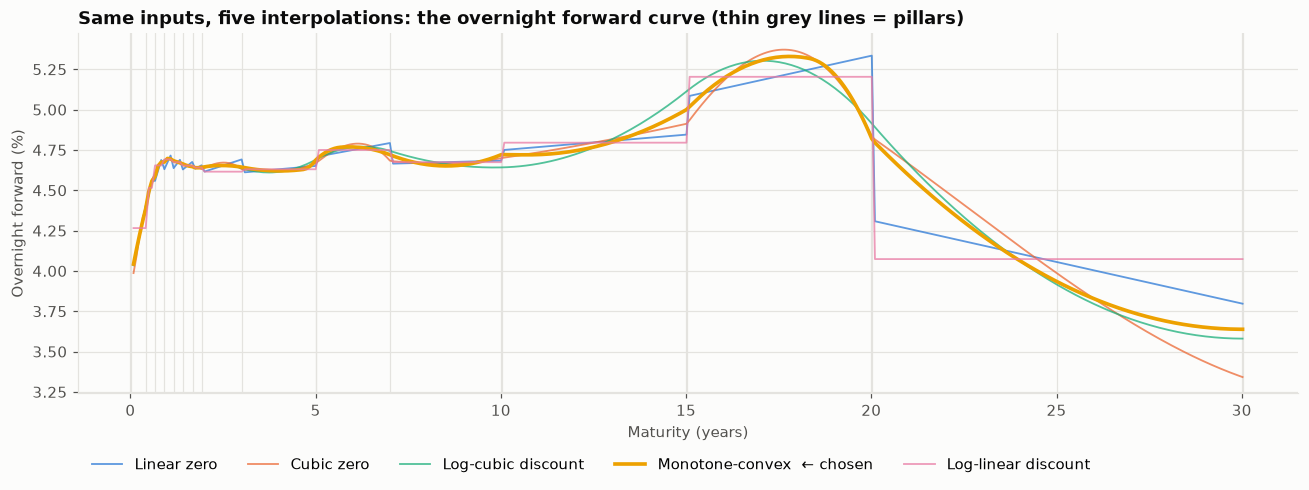

In [13]:
# --- Chart 4: forward curves by interpolation method
fig, ax = plt.subplots(figsize=(12, 4.6))
for i, (name, fwd) in enumerate(forward_curves.items()):
    is_chosen = name == CHOSEN_METHOD
    ax.plot(
        GRID_YEARS,
        fwd / 100,
        color=PALETTE[i],
        lw=2.4 if is_chosen else 1.2,
        alpha=1 if is_chosen else 0.75,
        label=name + ("  ← chosen" if is_chosen else ""),
    )
pillar_years = [
    CURVE_DAY_COUNT.yearFraction(ql_today, ql.DateParser.parseISO(p))
    for p in sofr_inputs["pillar"]
]
for x in pillar_years:
    ax.axvline(x, color=GRID, lw=0.8, zorder=0)
ax.set_title(
    "Same inputs, five interpolations: the overnight forward curve (thin grey"
    " lines = pillars)"
)
ax.set_xlabel("Maturity (years)")
ax.set_ylabel("Overnight forward (%)")
ax.legend(ncol=5, loc="upper left", bbox_to_anchor=(0, -0.14))
plt.tight_layout()
save_fig(fig, "03_forward_curves_by_interpolation")
plt.show()

### 7.2 The chosen curve reprices every input

A curve that does not give back its own inputs is not a curve. The table below lists each instrument, its market quote and the quote implied by the final curve. Futures errors are in price points × 100, so 0.01 = one basis point; swaps and the deposit are in basis points.

In [14]:
sofr_curve, sofr_inputs, sofr_quotes = build_sofr_curve(
    INTERPOLATION_METHODS[CHOSEN_METHOD]
)
ust_curve = build_treasury_curve(INTERPOLATION_METHODS[CHOSEN_METHOD])

check = sofr_inputs.drop(columns="helper").copy()
check["implied"] = [h.impliedQuote() for h in sofr_inputs["helper"]]
check["market"] = [h.quote().value() for h in sofr_inputs["helper"]]
check["error_bp"] = np.where(
    check["type"] == "Future",
    (check["implied"] - check["market"]) * 100,
    (check["implied"] - check["market"]) * 1e4,
)
print(f"Largest repricing error: {check['error_bp'].abs().max():.6f} bp")
check[["type", "instrument", "pillar", "quote_%", "error_bp"]]

Largest repricing error: 0.000000 bp


,type,instrument,pillar,quote_%,error_bp
0,Deposit,ON,2026-10-19,3.8900,0.0000
1,Future,SR3Z26,2027-03-17,4.2300,-0.0000
2,Future,SR3H27,2027-06-16,4.4800,-0.0000
3,Future,SR3M27,2027-09-15,4.6200,0.0000
4,Future,SR3U27,2027-12-15,4.6600,0.0000
5,Future,SR3Z27,2028-03-15,4.6450,0.0000
6,Future,SR3H28,2028-06-21,4.6300,-0.0000
7,Future,SR3M28,2028-09-20,4.6200,-0.0000
8,OIS swap,OIS 3Y,2029-10-22,4.6200,0.0000
9,OIS swap,OIS 5Y,2031-10-20,4.6400,-0.0000


### 7.3 How much does the swap-spread assumption matter?

The long end rests on an assumption, so we stress it. The curve is rebuilt with **no swap spread** (pure Treasury par yields) and with the spread **1.5×** larger, and we report the change in zero rates. If a downstream number (a PFE, a hedge ratio) is sensitive to differences of this size, it should not be signed off on this curve; use a curve built from observed swap rates instead.

In [15]:
def zero_pct(curve, years):
    return (
        curve.zeroRate(
            ql_today + ql.Period(int(years * 12), ql.Months),
            CURVE_DAY_COUNT,
            ql.Continuous,
        ).rate()
        * 100
    )


method_cls = INTERPOLATION_METHODS[CHOSEN_METHOD]
variants = {
    "no spread": build_sofr_curve(method_cls, 0.0)[0],
    "base case": sofr_curve,
    "1.5× spread": build_sofr_curve(method_cls, 1.5)[0],
}
sens = pd.DataFrame(
    {
        name: [zero_pct(c, t) for t in (2, 5, 10, 20, 30)]
        for name, c in variants.items()
    },
    index=["2Y", "5Y", "10Y", "20Y", "30Y"],
)
sens["no spread − base (bp)"] = (sens["no spread"] - sens["base case"]) * 100
sens["1.5× − base (bp)"] = (sens["1.5× spread"] - sens["base case"]) * 100
sens.round(3)

,no spread,base case,1.5× spread,no spread − base (bp),1.5× − base (bp)
2Y,4.5510,4.5420,4.5370,0.9030,-0.4570
5Y,4.8490,4.5990,4.4740,25.0550,-12.4950
10Y,5.0680,4.6520,4.4450,41.6830,-20.6560
20Y,5.5770,4.8270,4.4640,75.0720,-36.3030
30Y,5.4240,4.5610,4.1510,86.2570,-41.0520


## 8. Results

### 8.1 Curve tables

Zero rates, 3-month forwards and discount factors on a clean tenor grid, for SOFR and Treasuries. The full monthly curve is saved to `outputs/` for anyone who wants to reuse it.

In [16]:
def curve_table(curve, months):
    rows = []
    for m in months:
        d = ql_today + ql.Period(m, ql.Months)
        rows.append({
            "tenor_years": m / 12,
            "zero_%": (
                curve.zeroRate(d, CURVE_DAY_COUNT, ql.Continuous).rate() * 100
            ),
            "fwd_3m_%": (
                curve.forwardRate(
                    d, d + ql.Period(3, ql.Months), ql.Actual360(), ql.Simple
                ).rate()
                * 100
            ),
            "discount": curve.discount(d),
        })
    return pd.DataFrame(rows)


monthly = list(range(1, 361))
sofr_table, ust_table = curve_table(sofr_curve, monthly), curve_table(
    ust_curve, monthly
)
full = sofr_table.merge(
    ust_table, on="tenor_years", suffixes=("_sofr", "_ust")
)
full.insert(0, "eval_date", EVAL_DATE.isoformat())
full.to_csv(OUT_DIR / "sofr_and_treasury_curves_monthly.csv", index=False)

key = full[
    full["tenor_years"].isin([0.25, 0.5, 1, 2, 3, 5, 7, 10, 20, 30])
].set_index("tenor_years")
key["sofr_minus_ust_bp"] = (key["zero_%_sofr"] - key["zero_%_ust"]) * 100
key[[
    "zero_%_sofr",
    "fwd_3m_%_sofr",
    "discount_sofr",
    "zero_%_ust",
    "sofr_minus_ust_bp",
]]

,zero_%_sofr,fwd_3m_%_sofr,discount_sofr,zero_%_ust,sofr_minus_ust_bp
tenor_years,,,,,
0.2500,4.0866,4.3171,0.9898,4.2332,-14.6569
0.5000,4.2187,4.5373,0.9792,4.3054,-8.6727
1.0000,4.4226,4.6519,0.9567,4.3856,3.7080
2.0000,4.5420,4.6124,0.9130,4.6857,-14.3679
3.0000,4.5782,4.6018,0.8716,4.7675,-18.9250
5.0000,4.5989,4.6747,0.7945,4.8396,-24.0638
7.0000,4.6420,4.6729,0.7224,4.9353,-29.3260
10.0000,4.6517,4.6840,0.6278,5.0598,-40.8099
20.0000,4.8266,4.7492,0.3806,5.5518,-72.5204


### 8.2 Curve dashboard

One page for a risk committee: the two curves, the market-implied path of SOFR, the interpolation check, and the key rates. The interactive version (hover for exact values) is saved as HTML. A static PNG copy is saved for GitHub, which cannot render interactive Plotly charts.

In [17]:
yrs = full["tenor_years"]
kpi = {
    "SOFR fixing": sofr_today,
    "SOFR 2Y": zero_pct(sofr_curve, 2),
    "SOFR 10Y": zero_pct(sofr_curve, 10),
    "SOFR 30Y": zero_pct(sofr_curve, 30),
    "2s10s (bp)": (zero_pct(sofr_curve, 10) - zero_pct(sofr_curve, 2)) * 100,
}

dash = make_subplots(
    rows=2,
    cols=2,
    vertical_spacing=0.14,
    horizontal_spacing=0.08,
    specs=[[{}, {}], [{}, {"type": "table"}]],
    subplot_titles=(
        "Zero curves: SOFR vs Treasury",
        "Market-implied path of SOFR (next 3 years)",
        f"Overnight forwards by interpolation (chosen: {CHOSEN_METHOD})",
        "Key rates (%)",
    ),
)

# (1) zero curves
dash.add_trace(
    go.Scatter(
        x=yrs,
        y=full["zero_%_sofr"],
        name="SOFR zero",
        line=dict(color=PALETTE[0], width=2),
    ),
    1,
    1,
)
dash.add_trace(
    go.Scatter(
        x=yrs,
        y=full["zero_%_ust"],
        name="Treasury zero",
        line=dict(color=PALETTE[1], width=2),
    ),
    1,
    1,
)

# (2) SOFR history + forward path + futures points
hist = sofr_fixings.loc[pd.Timestamp(EVAL_DATE) - pd.Timedelta(days=365) :]
path_dates = [
    EVAL_DATE + dt.timedelta(days=int(t * 365)) for t in yrs[yrs <= 3]
]
dash.add_trace(
    go.Scatter(
        x=hist.index,
        y=hist.values,
        name="SOFR fixing",
        line=dict(color=PALETTE[0], width=2),
    ),
    1,
    2,
)
dash.add_trace(
    go.Scatter(
        x=path_dates,
        y=full.loc[yrs <= 3, "fwd_3m_%_sofr"],
        name="3M forward (curve)",
        line=dict(color=PALETTE[1], width=2),
    ),
    1,
    2,
)
dash.add_trace(
    go.Scatter(
        x=futures_used["ref_start"],
        y=futures_used["implied_rate"],
        name="Futures-implied",
        mode="markers",
        marker=dict(
            color=PALETTE[2], size=8, line=dict(color=SURFACE, width=2)
        ),
    ),
    1,
    2,
)

# (3) forwards by interpolation
for i, (name, fwd) in enumerate(forward_curves.items()):
    dash.add_trace(
        go.Scatter(
            x=GRID_YEARS,
            y=fwd / 100,
            name=name,
            legendgroup="interp",
            line=dict(
                color=PALETTE[i], width=2.6 if name == CHOSEN_METHOD else 1.2
            ),
        ),
        2,
        1,
    )

# (4) key-rate table
dash.add_trace(
    go.Table(
        header=dict(
            values=[
                "Tenor",
                "SOFR zero",
                "SOFR 3M fwd",
                "UST zero",
                "SOFR − UST (bp)",
            ],
            fill_color="#f1f0ec",
            font=dict(color=INK, size=12),
            align="left",
        ),
        cells=dict(
            values=[
                [f"{t:g}Y" for t in key.index],
                key["zero_%_sofr"].round(3),
                key["fwd_3m_%_sofr"].round(3),
                key["zero_%_ust"].round(3),
                key["sofr_minus_ust_bp"].round(1),
            ],
            fill_color=SURFACE,
            font=dict(color=INK_2, size=11),
            align="left",
        ),
    ),
    2,
    2,
)

title = (
    f"<b>SOFR curve dashboard · {EVAL_DATE:%d %b %Y}</b><br><span"
    f" style='font-size:13px;color:{INK_2}'>"
    + " · ".join(
        f"{k}: {v:.2f}" if "bp" not in k else f"{k}: {v:+.0f}"
        for k, v in kpi.items()
    )
    + "</span>"
)
dash.update_layout(
    title=dict(text=title, x=0.01),
    height=860,
    width=1300,
    template="plotly_white",
    paper_bgcolor=SURFACE,
    plot_bgcolor=SURFACE,
    font=dict(color=INK_2),
    legend=dict(orientation="h", y=-0.06),
    hovermode="x unified",
    margin=dict(t=110),
)
dash.update_xaxes(title_text="Maturity (years)", row=1, col=1)
dash.update_xaxes(title_text="Maturity (years)", row=2, col=1)
dash.update_yaxes(title_text="%", row=1, col=1)
dash.update_yaxes(title_text="%", row=1, col=2)
dash.update_yaxes(title_text="%", row=2, col=1)

dash.write_html(OUT_DIR / "dashboard.html", include_plotlyjs="cdn")
try:
    dash.write_image(OUT_DIR / "dashboard.png", scale=2)
    print("Dashboard saved: outputs/dashboard.html and outputs/dashboard.png")
except Exception as err:
    print(
        f"Dashboard saved as HTML. PNG export skipped ({type(err).__name__}):"
        " kaleido needs Google Chrome; run `plotly_get_chrome` in the"
        " terminal once."
    )
dash.show()

Dashboard saved: outputs/dashboard.html and outputs/dashboard.png


### 8.3 Reading the results

- **The futures strip prices the path of policy.** The orange line in the second panel is the market's expected SOFR. When it slopes down, the market prices rate cuts, and the size of the drop over the next year is a quick read of how many.
- **SOFR sits below Treasuries at the long end.** That is the negative swap spread by construction. The sensitivity table in 7.3 shows how many basis points of the long-end zero rate depend on that one assumption.
- **Interpolation is a risk decision, not a cosmetic one.** Flat-forward and linear methods reprice perfectly but produce step or saw-tooth forwards. Cubic splines are smooth but leak a 5-year move into the 20–30-year forwards, which would show up as phantom key-rate risk in a hedge report. The selection rule makes this trade-off explicit instead of leaving it to habit.

## 9. Limitations and extensions

- **The long end is an approximation.** Real SOFR swap quotes, or swap trades reported to a public repository (DTCC), would replace *Treasury + spread*.
- **No turn-of-year or meeting-date effects.** A production curve adds jumps on FOMC meeting dates and at year-end. QuantLib supports this through the `jumps` argument of the piecewise curves.
- **Single-curve set-up.** SOFR is both the projection and the discount curve here, which is correct for SOFR-collateralised swaps. Instruments under other CSAs need a different discount curve.
- **Convexity is a simple closed form.** A calibrated Hull–White model would give a consistent adjustment for longer contracts.

## References

### Finance and regulation

- Hagan, P. S., & West, G. (2006). Interpolation methods for curve construction. *Applied Mathematical Finance, 13*(2), 89–129. https://doi.org/10.1080/13504860500396032
- Ametrano, F. M., & Bianchetti, M. (2013). *Everything you always wanted to know about multiple interest rate curve bootstrapping but were afraid to ask*. SSRN. https://doi.org/10.2139/ssrn.2219548
- Jermann, U. J. (2020). Negative swap spreads and limited arbitrage. *The Review of Financial Studies, 33*(1), 212–238. https://doi.org/10.1093/rfs/hhz030
- Hull, J., & White, A. (1990). Pricing interest-rate-derivative securities. *The Review of Financial Studies, 3*(4), 573–592. https://doi.org/10.1093/rfs/3.4.573
- Mercurio, F. (2018). *A simple multi-curve model for pricing SOFR futures and other derivatives*. SSRN. https://doi.org/10.2139/ssrn.3225872

### Machine learning and deep learning

- Ballabio, L. (2020). *Implementing QuantLib*. Leanpub. https://leanpub.com/implementingquantlib